In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/dataset_penjualan_kantin.csv")

df.head()

,id_transaksi,tanggal,nama_produk,kategori,jumlah_terjual,harga_satuan,nama_kasir,metode_pembayaran
0,TRX0042,2026-08-11,Roti Bakar,Makanan,9,7000,Pak Agus,Tunai
1,TRX0005,2026-08-03,Gorengan,makanan,2,2000,Bu Sri,QRIS
2,TRX0011,2026-08-04,Jus Alpukat,Minuman,4,NaN,Bu Wati,Tunai
3,TRX0035,2026-08-10,Mie Ayam,Makanan,NaN,10000,Pak Joko,Transfer
4,TRX0007,2026-08-03,Kerupuk,Snack,10,Rp2.000,Bu Wati,Transfer


In [ ]:
print("Jumlah baris dan kolom:")
print(df.shape)

Jumlah baris dan kolom:
(69, 8)


In [ ]:
df.columns

Index(['id_transaksi', 'tanggal', 'nama_produk', 'kategori', 'jumlah_terjual',
       'harga_satuan', 'nama_kasir', 'metode_pembayaran'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   id_transaksi       69 non-null     object
 1   tanggal            69 non-null     object
 2   nama_produk        69 non-null     object
 3   kategori           69 non-null     object
 4   jumlah_terjual     65 non-null     object
 5   harga_satuan       66 non-null     object
 6   nama_kasir         66 non-null     object
 7   metode_pembayaran  69 non-null     object
dtypes: object(8)
memory usage: 4.4+ KB


In [ ]:
df.isnull().sum()

,0
id_transaksi,0
tanggal,0
nama_produk,0
kategori,0
jumlah_terjual,4
harga_satuan,3
nama_kasir,3
metode_pembayaran,0


In [ ]:
df.duplicated().sum()

np.int64(4)

In [ ]:
df = df.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:")
print(df.shape)

Jumlah data setelah menghapus duplikat:
(65, 8)


In [ ]:
df["kategori"] = df["kategori"].str.strip().str.title()

df["kategori"].unique()

array(['Makanan', 'Minuman', 'Snack'], dtype=object)

In [ ]:
df["jumlah_terjual"] = (
    df["jumlah_terjual"]
    .astype(str)
    .str.replace(" pcs", "", regex=False)
)

In [ ]:
df["jumlah_terjual"] = pd.to_numeric(
    df["jumlah_terjual"],
    errors="coerce"
)

In [ ]:
df["jumlah_terjual"].head(10)

,jumlah_terjual
0,9.0
1,2.0
2,4.0
3,NaN
4,10.0
5,9.0
6,14.0
7,14.0
8,NaN
9,14.0


In [ ]:
df["harga_satuan"] = (
    df["harga_satuan"]
    .astype(str)
    .str.replace("Rp", "", regex=False)
    .str.replace(".", "", regex=False)
)

In [ ]:
df["harga_satuan"] = pd.to_numeric(
    df["harga_satuan"],
    errors="coerce"
)

In [ ]:
df["harga_satuan"].head(10)

,harga_satuan
0,7000.0
1,2000.0
2,NaN
3,10000.0
4,2000.0
5,5000.0
6,5000.0
7,10000.0
8,12000.0
9,8000.0


In [ ]:
bulan = {
    "Januari": "01",
    "Februari": "02",
    "Maret": "03",
    "April": "04",
    "Mei": "05",
    "Juni": "06",
    "Juli": "07",
    "Agustus": "08",
    "September": "09",
    "Oktober": "10",
    "November": "11",
    "Desember": "12"
}

for nama, angka in bulan.items():
    df["tanggal"] = df["tanggal"].str.replace(
        nama,
        angka,
        regex=False
    )

In [ ]:
df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    dayfirst=True,
    errors="coerce"
)

In [ ]:
df["tanggal"].head(10)

,tanggal
0,2026-11-08
1,2026-03-08
2,2026-04-08
3,2026-10-08
4,2026-03-08
5,2026-11-08
6,NaT
7,NaT
8,NaT
9,NaT


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

display(df.head())


Saving dataset_penjualan_kantin (1).csv to dataset_penjualan_kantin (1) (1).csv
Dataset berhasil dimuat!
Ukuran dataset: (69, 8)


,id_transaksi,tanggal,nama_produk,kategori,jumlah_terjual,harga_satuan,nama_kasir,metode_pembayaran
0,TRX0042,2026-08-11,Roti Bakar,Makanan,9,7000,Pak Agus,Tunai
1,TRX0005,2026-08-03,Gorengan,makanan,2,2000,Bu Sri,QRIS
2,TRX0011,2026-08-04,Jus Alpukat,Minuman,4,NaN,Bu Wati,Tunai
3,TRX0035,2026-08-10,Mie Ayam,Makanan,NaN,10000,Pak Joko,Transfer
4,TRX0007,2026-08-03,Kerupuk,Snack,10,Rp2.000,Bu Wati,Transfer


In [ ]:

# Membersihkan kolom jumlah_terjual
df["jumlah_terjual"] = (
    df["jumlah_terjual"]
    .astype(str)
    .str.replace(r"\s*pcs\s*", "", regex=True)
    .str.strip()
)

# Mengubah data menjadi angka
df["jumlah_terjual"] = pd.to_numeric(
    df["jumlah_terjual"],
    errors="coerce"
)

# Memeriksa hasil
print(df["jumlah_terjual"].head(15))
print("\nTipe data:", df["jumlah_terjual"].dtype)


0      9.0
1      2.0
2      4.0
3      NaN
4     10.0
5      9.0
6     14.0
7     14.0
8      NaN
9     14.0
10     1.0
11     3.0
12    12.0
13     7.0
14    15.0
Name: jumlah_terjual, dtype: float64

Tipe data: float64


In [ ]:

# Membersihkan harga satuan
df["harga_satuan"] = (
    df["harga_satuan"]
    .astype(str)
    .str.replace("Rp", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.strip()
)

df["harga_satuan"] = pd.to_numeric(
    df["harga_satuan"],
    errors="coerce"
)

print(df["harga_satuan"].head(15))
print("\nTipe data:", df["harga_satuan"].dtype)


0      7000.0
1      2000.0
2         NaN
3     10000.0
4      2000.0
5      5000.0
6      5000.0
7     10000.0
8     12000.0
9      8000.0
10     4000.0
11     7000.0
12     5000.0
13     2000.0
14     3000.0
Name: harga_satuan, dtype: float64

Tipe data: float64


In [ ]:

# Mengisi nilai kosong dengan median
df["jumlah_terjual"] = df["jumlah_terjual"].fillna(
    df["jumlah_terjual"].median()
)

df["harga_satuan"] = df["harga_satuan"].fillna(
    df["harga_satuan"].median()
)

# Mengisi nama kasir kosong dengan modus
df["nama_kasir"] = df["nama_kasir"].fillna(
    df["nama_kasir"].mode()[0]
)

print("Missing value setelah cleaning:")
print(df.isnull().sum())


Missing value setelah cleaning:
id_transaksi         0
tanggal              0
nama_produk          0
kategori             0
jumlah_terjual       0
harga_satuan         0
nama_kasir           0
metode_pembayaran    0
dtype: int64


In [ ]:
df["jumlah_terjual"] = df["jumlah_terjual"].fillna(
    df["jumlah_terjual"].median()
)

In [ ]:
df["harga_satuan"] = df["harga_satuan"].fillna(
    df["harga_satuan"].median()
)

In [ ]:
df["nama_kasir"] = df["nama_kasir"].fillna(
    df["nama_kasir"].mode()[0]
)

In [ ]:
print("Missing value:")
print(df.isnull().sum())

print("\nDuplikat:")
print(df.duplicated().sum())

Missing value:
id_transaksi         0
tanggal              0
nama_produk          0
kategori             0
jumlah_terjual       0
harga_satuan         0
nama_kasir           0
metode_pembayaran    0
dtype: int64

Duplikat:
4


In [ ]:
df["total_penjualan"] = (
    df["jumlah_terjual"] *
    df["harga_satuan"]
)

In [ ]:
df.head()

,id_transaksi,tanggal,nama_produk,kategori,jumlah_terjual,harga_satuan,nama_kasir,metode_pembayaran,total_penjualan
0,TRX0042,2026-08-11,Roti Bakar,Makanan,9.0,7000.0,Pak Agus,Tunai,63000.0
1,TRX0005,2026-08-03,Gorengan,makanan,2.0,2000.0,Bu Sri,QRIS,4000.0
2,TRX0011,2026-08-04,Jus Alpukat,Minuman,4.0,8000.0,Bu Wati,Tunai,32000.0
3,TRX0035,2026-08-10,Mie Ayam,Makanan,8.0,10000.0,Pak Joko,Transfer,80000.0
4,TRX0007,2026-08-03,Kerupuk,Snack,10.0,2000.0,Bu Wati,Transfer,20000.0


In [ ]:
makanan = df[df["kategori"] == "Makanan"]

makanan.head()

,id_transaksi,tanggal,nama_produk,kategori,jumlah_terjual,harga_satuan,nama_kasir,metode_pembayaran,total_penjualan
0,TRX0042,2026-08-11,Roti Bakar,Makanan,9.0,7000.0,Pak Agus,Tunai,63000.0
3,TRX0035,2026-08-10,Mie Ayam,Makanan,8.0,10000.0,Pak Joko,Transfer,80000.0
11,TRX0052,2026-08-12,Roti Bakar,Makanan,3.0,7000.0,Bu Wati,Tunai,21000.0
17,TRX0014,2026-08-05,Bakso,Makanan,9.0,11000.0,Pak Agus,Tunai,99000.0
19,TRX0034,2026-08-10,Bakso,Makanan,1.0,11000.0,Bu Sri,QRIS,11000.0


In [ ]:
df.sort_values(
    "jumlah_terjual",
    ascending=False
).head(10)

,id_transaksi,tanggal,nama_produk,kategori,jumlah_terjual,harga_satuan,nama_kasir,metode_pembayaran,total_penjualan
59,TRX0050,2026-08-12,Roti Bakar,MAKANAN,500.0,7000.0,Pak Joko,QRIS,3500000.0
20,TRX0046,2026-08-11,Nasi Goreng,Makanan,15.0,12000.0,Bu Wati,QRIS,180000.0
14,TRX0048,2026-08-12,Keripik Singkong,snack,15.0,3000.0,Bu Wati,QRIS,45000.0
16,TRX0054,13 Agustus 2026,Jus Alpukat,Minuman,15.0,8000.0,Pak Joko,Tunai,120000.0
9,TRX0057,13/08/2026,Jus Alpukat,MINUMAN,14.0,8000.0,Bu Sri,Tunai,112000.0
57,TRX0049,2026-08-12,Es Teh,MINUMAN,14.0,3000.0,Bu Sri,QRIS,42000.0
63,TRX0057,13/08/2026,Jus Alpukat,MINUMAN,14.0,8000.0,Bu Sri,Tunai,112000.0
29,TRX0029,2026-08-07,Nasi Uduk,Makanan,14.0,8000.0,Bu Sri,QRIS,112000.0
6,TRX0061,14 Agustus 2026,Teh Botol,MINUMAN,14.0,5000.0,Bu Sri,QRIS,70000.0
7,TRX0008,4 Agustus 2026,Mie Ayam,makanan,14.0,10000.0,Pak Joko,Tunai,140000.0


In [ ]:
produk_terlaris = df.groupby(
    "nama_produk"
)["jumlah_terjual"].sum().sort_values(
    ascending=False
)

produk_terlaris

,jumlah_terjual
nama_produk,
Roti Bakar,532.0
Nasi Goreng,90.0
Jus Alpukat,76.0
Mie Ayam,63.0
Teh Botol,58.0
Kerupuk,54.0
Keripik Singkong,32.0
Bakso,32.0
Es Teh,31.0


In [ ]:
produk_terlaris.head(1)

,jumlah_terjual
nama_produk,
Roti Bakar,532.0


In [ ]:
total_produk = df.groupby(
    "nama_produk"
)["total_penjualan"].sum().sort_values(
    ascending=False
)

total_produk

,total_penjualan
nama_produk,
Roti Bakar,3724000.0
Nasi Goreng,1076000.0
Mie Ayam,630000.0
Jus Alpukat,608000.0
Bakso,352000.0
Teh Botol,290000.0
Nasi Uduk,168000.0
Kerupuk,108000.0
Keripik Singkong,96000.0


In [ ]:
total_produk.head(1)

,total_penjualan
nama_produk,
Roti Bakar,3724000.0


In [ ]:
penjualan_kategori = df.groupby(
    "kategori"
)["total_penjualan"].sum().sort_values(
    ascending=False
)

penjualan_kategori

,total_penjualan
kategori,
MAKANAN,3924000.0
Makanan,1289000.0
makanan,755000.0
MINUMAN,639000.0
Minuman,299000.0
Snack,105000.0
minuman,89000.0
snack,69000.0
SNACK,30000.0


In [ ]:
penjualan_kategori.head(1)

,total_penjualan
kategori,
MAKANAN,3924000.0


In [ ]:
metode_pembayaran = df["metode_pembayaran"].value_counts()

metode_pembayaran

,count
metode_pembayaran,
QRIS,36
Tunai,25
Transfer,8


In [ ]:
metode_pembayaran.head(1)

,count
metode_pembayaran,
QRIS,36


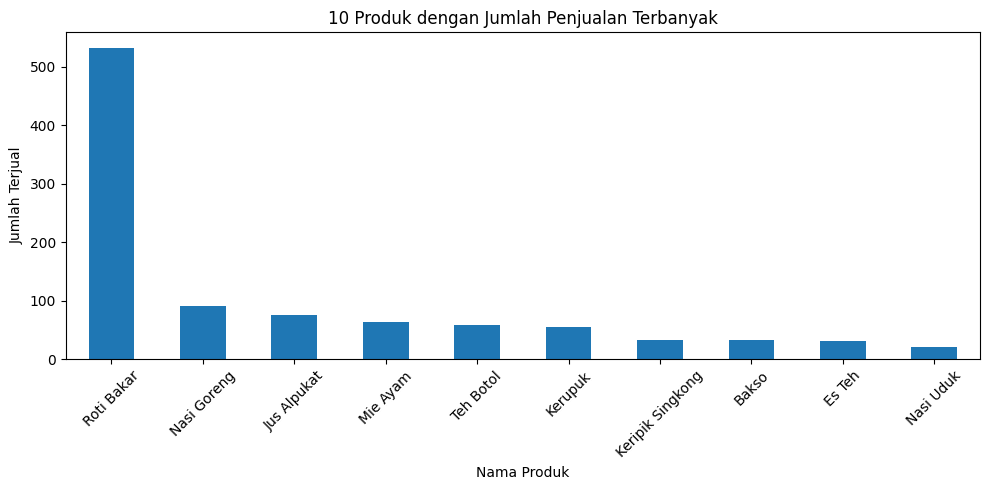

In [ ]:
produk_terlaris.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="10 Produk dengan Jumlah Penjualan Terbanyak"
)

plt.xlabel("Nama Produk")
plt.ylabel("Jumlah Terjual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

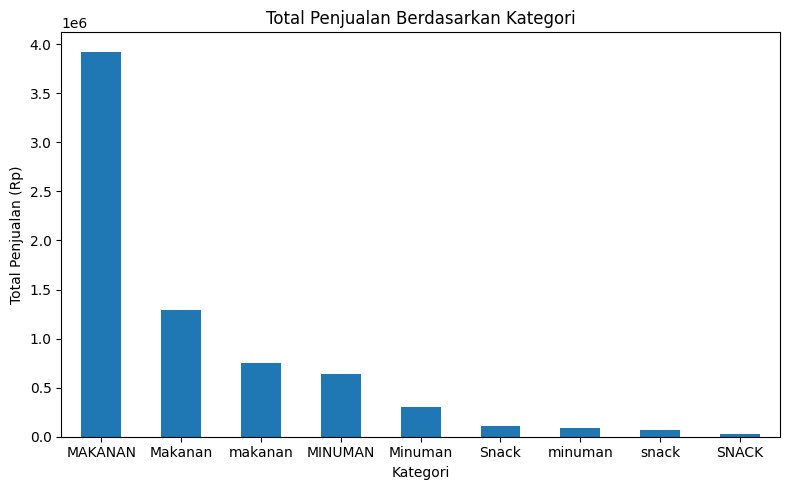

In [ ]:
penjualan_kategori.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Penjualan Berdasarkan Kategori"
)

plt.xlabel("Kategori")
plt.ylabel("Total Penjualan (Rp)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

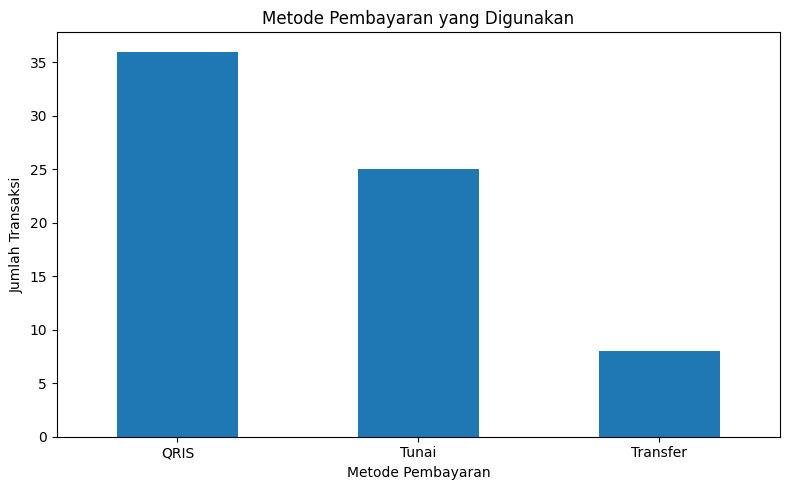

In [ ]:
metode_pembayaran.plot(
    kind="bar",
    figsize=(8, 5),
    title="Metode Pembayaran yang Digunakan"
)

plt.xlabel("Metode Pembayaran")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv(
    "dataset_penjualan_kantin_clean.csv",
    index=False
)

📒 EDA Penjualan Kantin - Nagata & Arlen

│
├── 1. Import Library
│
├── 2. Data Loading
│
├── 3. Data Inspection
│
├── 4. Data Cleaning
│   ├── Hapus duplikat
│   ├── Missing value
│   ├── Bersihkan harga
│   ├── Bersihkan jumlah
│   ├── Bersihkan tanggal
│   └── Seragamkan kategori
│
├── 5. Data Manipulation
│   ├── Total penjualan
│   ├── Filter
│   └── Sort
│
├── 6. Exploratory Data Analysis
│   ├── Produk terlaris
│   ├── Kategori terbesar
│   └── Metode pembayaran
│
├── 7. Visualisasi
│   ├── Grafik produk
│   ├── Grafik kategori
│   └── Grafik pembayaran
│
└── 8. Kesimpulan